# Frozen nested evaluation: results and limitations

This is the interpretation entry point for the completed `real-20261109-v1` experiment. It loads saved predictions and verifies their checksums; **it does not fit models, select new thresholds, or change the frozen protocol**. The original 100 Hz CNN has 6,000 samples per minute and 3,009 parameters.

The evaluation is retrospective and exploratory: subject identities are unverified, groups are literature-derived, and this cohort had prior test exposure. These results do not establish patient-independent or clinical performance. Historical single-split results in Notebooks 02–04 are separate experiments.

Run top to bottom with the project kernel. Tables and plots are written to a new timestamped directory under ignored `reports/portfolio-v2/`. The accompanying tracked report is `docs/portfolio-nested-results.md`.

In [1]:
import hashlib
import json
import os
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import average_precision_score, confusion_matrix

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RUN = ROOT / "data/processed/portfolio-v2/plan001-real-20261108"
RESULTS = RUN / "full/real-20261109-v1/results"
SOURCE = ROOT / "notebooks/08_nested_evaluation.ipynb"
run_tag = os.environ.get("APNEA_RESULTS_TAG", datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ"))
if not run_tag or Path(run_tag).name != run_tag or run_tag in {".", ".."}:
    raise ValueError("Invalid output tag")
OUT = ROOT / "reports/portfolio-v2/nested-interpretation" / run_tag

manifest = json.loads((RESULTS / "manifest.json").read_text())
assert manifest["status"] == "complete" and not manifest["synthetic"]
for name, expected in manifest["artifacts"].items():
    assert hashlib.sha256((RESULTS / name).read_bytes()).hexdigest() == expected, name
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == manifest["context"]["runner_sha256"]
freeze_manifest = json.loads((RUN / "freeze/manifest.json").read_text())
assert freeze_manifest["identity_hash"] == manifest["context"]["freeze_id"]
OUT.mkdir(parents=True, exist_ok=False)
metrics = pd.read_csv(RESULTS / "metrics.csv")
predictions = pd.read_parquet(RESULTS / "outer_predictions.parquet")
uncertainty = pd.read_csv(RESULTS / "uncertainty.csv")
choices = pd.DataFrame(json.loads((RESULTS / "selected_configurations.json").read_text()))
print(f"Verified {len(manifest['artifacts'])} artifact hashes. Output: {OUT}")
print("Freeze:", manifest["context"]["freeze_id"])

Verified 140 artifact hashes. Output: <project-root>/reports/portfolio-v2/nested-interpretation/results-20261110-v2
Freeze: 1765caa330e2136b1f16f61828fae0a568bcc36b0730bd3b2cfd9b3d7e2f1363


## Prediction and metric checks

Every configuration must cover the same 16,558 cohort windows exactly once. Independently recompute each primary-seed model's fold AP and confusion counts from predictions. These checks verify the interpretation against the saved outputs; they do not validate the underlying patient grouping.

In [2]:
keys = ["record_id", "minute"]
configuration = ["analysis", "model", "feature_set", "seed"]
assert not predictions.duplicated(configuration + keys).any()
cohort = pd.read_parquet(RUN / "protocol/cohort.parquet")
expected_keys = set(map(tuple, cohort[keys].to_numpy()))
assert len(expected_keys) == 16558
for _, part in predictions.groupby(configuration):
    assert set(map(tuple, part[keys].to_numpy())) == expected_keys
    assert part.groupby("subject_group").outer_fold.nunique().max() == 1
primary = predictions.query("analysis == 'tuned' and seed == 67").copy()
folds = metrics.query("analysis == 'tuned' and seed == 67 and level == 'fold'").copy()
folds["outer_fold"] = folds.identifier.astype(int)
for (model, fold), part in primary.groupby(["model", "outer_fold"]):
    saved = folds[folds.model.eq(model) & folds.outer_fold.eq(fold)].iloc[0]
    assert np.isclose(average_precision_score(part.label, part.score), saved.average_precision)
    np.testing.assert_array_equal(
        confusion_matrix(part.label, part.prediction, labels=[0, 1]).ravel(),
        saved[["tn", "fp", "fn", "tp"]].to_numpy(dtype=int),
    )
assert primary.groupby("model").size().eq(16558).all()
print("29 configurations checked; primary fold metrics match saved predictions.")
assert predictions.groupby(configuration).ngroups == 29

29 configurations checked; primary fold metrics match saved predictions.


## Primary comparison and fold variability

The prespecified outcome is the **unweighted mean of five outer-fold AP scores**. Fold SD is descriptive, not a confidence interval. Pooled AP/AUC combine scores from different fitted models and are reported separately. A constant scorer's mean fold AP is 0.395 (mean fold prevalence); pooled cohort prevalence is 0.393. AP is not accuracy.

Compare pipelines, not only classifier families: classical F2 models share six RR features, the adapted SVM uses 11 local RR features, and the CNN uses filtered waveforms. Equal candidate counts do not guarantee equal optimization difficulty.

,mean_fold_ap,fold_sd,pooled_ap,pooled_auc,pooled_f1
model,,,,,
logistic_regression,0.646,0.137,0.594,0.708,0.568
linear_svm,0.603,0.171,0.560,0.684,0.569
xgboost,0.540,0.136,0.508,0.630,0.539
random_forest,0.502,0.098,0.499,0.633,0.540
cnn,0.474,0.101,0.432,0.548,0.523


outer_fold,0,1,2,3,4
model,,,,,
logistic_regression,0.662,0.476,0.856,0.614,0.623
linear_svm,0.633,0.438,0.849,0.651,0.444
xgboost,0.633,0.518,0.720,0.437,0.392
random_forest,0.459,0.535,0.657,0.448,0.408
cnn,0.366,0.486,0.406,0.631,0.483


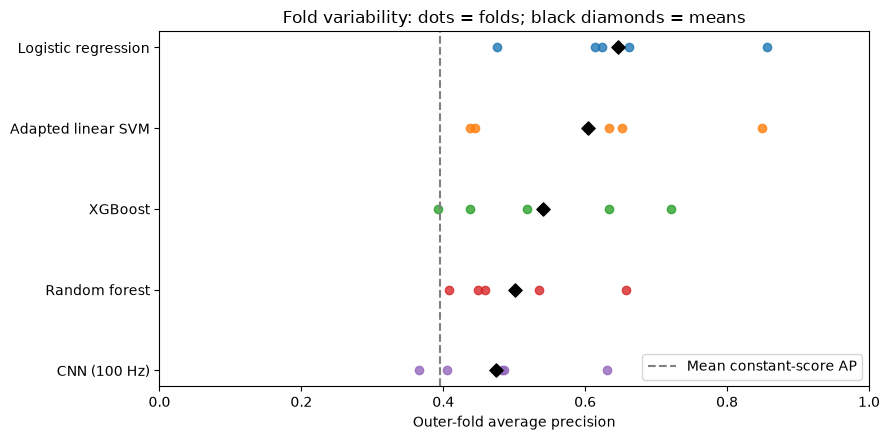

In [3]:
order = ["logistic_regression", "linear_svm", "xgboost", "random_forest", "cnn"]
labels = {
    "logistic_regression": "Logistic regression",
    "linear_svm": "Adapted linear SVM",
    "xgboost": "XGBoost",
    "random_forest": "Random forest",
    "cnn": "CNN (100 Hz)",
}
mean = metrics.query("analysis == 'tuned' and seed == 67 and level == 'fold_mean'")
pooled = metrics.query("analysis == 'tuned' and seed == 67 and level == 'pooled'")
headline = (
    mean.set_index("model")[["average_precision", "fold_ap_std"]]
    .rename(columns={"average_precision": "mean_fold_ap", "fold_ap_std": "fold_sd"})
    .join(
        pooled.set_index("model")[["average_precision", "roc_auc", "f1_score"]].rename(
            columns={
                "average_precision": "pooled_ap",
                "roc_auc": "pooled_auc",
                "f1_score": "pooled_f1",
            }
        )
    )
    .loc[order]
)
fold_table = folds.pivot(index="model", columns="outer_fold", values="average_precision").loc[order]
display(headline.round(3), fold_table.round(3))
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, model in enumerate(order):
    values = fold_table.loc[model].to_numpy()
    ax.scatter(values, np.full(5, i), alpha=0.8)
    ax.scatter(headline.loc[model, "mean_fold_ap"], i, marker="D", color="black", s=45)
ax.axvline(0.395293, linestyle="--", color="gray", label="Mean constant-score AP")
ax.set(
    yticks=range(5),
    yticklabels=[labels[x] for x in order],
    xlabel="Outer-fold average precision",
    title="Fold variability: dots = folds; black diamonds = means",
    xlim=(0, 1),
)
ax.invert_yaxis()
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(OUT / "fold_ap.png", dpi=160)
plt.show()

## Operating-point failures

Thresholds were chosen by maximum F1 on inner out-of-fold predictions, with the lowest threshold breaking ties. Outer labels never supplied threshold selection. A selected threshold can still fail to transfer. Here “all-positive” means every held-out window was predicted positive; it is not a missing-value or calculation error. An F1 near 0.57 can coexist with zero specificity.

The table includes all primary models and folds, not only the CNN. These are retrospective diagnostics; do not alter the thresholds after observing outer results.

,model,outer_fold,threshold,positive_rate,prevalence,n_windows,sensitivity,specificity,f1_score,tn,fp,fn,tp,all_positive,fold_number
0,cnn,0,0.425,0.758,0.319,3381,0.994,0.353,0.590,812.0,1489.0,6.0,1074.0,False,1
1,cnn,1,0.287,0.407,0.383,3887,0.551,0.682,0.535,1636.0,762.0,668.0,821.0,False,2
2,cnn,2,0.369,0.267,0.468,3031,0.154,0.634,0.197,1022.0,591.0,1199.0,219.0,False,3
3,cnn,3,0.247,1.000,0.399,3355,1.000,0.000,0.571,0.0,2016.0,0.0,1339.0,True,4
4,cnn,4,0.240,1.000,0.407,2904,1.000,0.000,0.579,0.0,1722.0,0.0,1182.0,True,5
5,linear_svm,0,-2.928,0.999,0.319,3381,1.000,0.002,0.485,5.0,2296.0,0.0,1080.0,False,1
6,linear_svm,1,-1.034,0.828,0.383,3887,0.852,0.186,0.539,446.0,1952.0,221.0,1268.0,False,2
7,linear_svm,2,-0.852,0.719,0.468,3031,0.977,0.508,0.771,820.0,793.0,32.0,1386.0,False,3
8,linear_svm,3,-0.736,0.337,0.399,3355,0.549,0.803,0.595,1619.0,397.0,604.0,735.0,False,4
9,linear_svm,4,-0.736,0.389,0.407,2904,0.439,0.645,0.449,1110.0,612.0,663.0,519.0,False,5


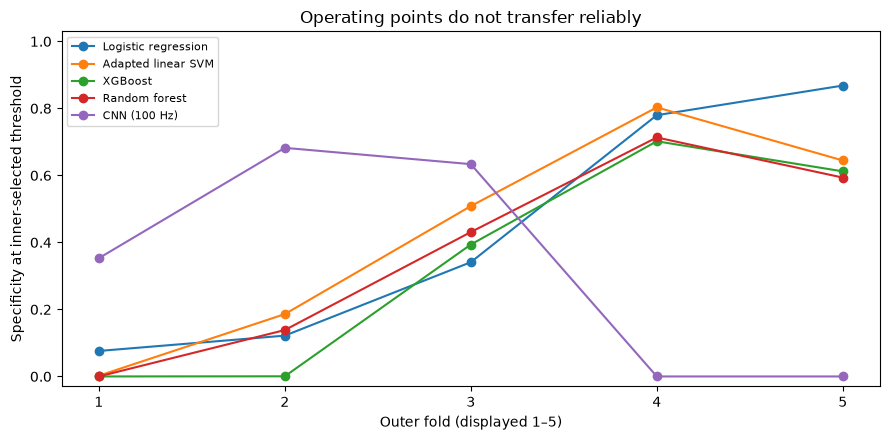

In [4]:
diagnostics = (
    primary.groupby(["model", "outer_fold"])
    .agg(
        threshold=("threshold", "first"),
        positive_rate=("prediction", "mean"),
        prevalence=("label", "mean"),
        n_windows=("label", "size"),
    )
    .reset_index()
)
diagnostics = diagnostics.merge(
    folds[
        ["model", "outer_fold", "sensitivity", "specificity", "f1_score", "tn", "fp", "fn", "tp"]
    ],
    on=["model", "outer_fold"],
    validate="one_to_one",
)
diagnostics["all_positive"] = diagnostics.positive_rate.eq(1)
diagnostics["fold_number"] = diagnostics.outer_fold + 1
failures = diagnostics[diagnostics.all_positive]
assert set(failures.query("model == 'cnn'").outer_fold) == {3, 4}
display(diagnostics.round(3))
fig, ax = plt.subplots(figsize=(9, 4.5))
for model in order:
    part = diagnostics[diagnostics.model.eq(model)]
    ax.plot(part.fold_number, part.specificity, marker="o", label=labels[model])
ax.set(
    xlabel="Outer fold (displayed 1–5)",
    ylabel="Specificity at inner-selected threshold",
    xticks=range(1, 6),
    ylim=(-0.03, 1.03),
    title="Operating points do not transfer reliably",
)
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "specificity.png", dpi=160)
plt.show()

## Seed sensitivity, fixed-setting contrasts and uncertainty

Seeds 167/267 refit the selected settings without another hyperparameter search. They are neither independent subjects nor an ensemble. Their spread does not measure cohort uncertainty.

RQ1 ablations use fixed settings. Comparing these with tuned F2 is descriptive; selecting whichever version scores better on the outer data would introduce another selection step. The bootstrap intervals below are for **pooled AP differences, XGBoost minus comparator**, conditional on fixed cross-fitted predictions. They are not intervals for mean fold AP, exclude full training/tuning uncertainty, and are not multiplicity-adjusted. No direct LR–CNN or LR–SVM interval was prespecified/exported.

In [5]:
seeds = (
    metrics.query("analysis == 'tuned' and level == 'fold_mean'")
    .pivot(index="model", columns="seed", values="average_precision")
    .reindex(order)
)
fixed = metrics.query("analysis == 'ablation' and level == 'fold_mean'").pivot(
    index="model", columns="feature_set", values="average_precision"
)
tuning = pd.DataFrame({"fixed_F2": fixed.B_F2, "tuned_F2": headline.mean_fold_ap}).dropna()
tuning["difference"] = tuning.tuned_F2 - tuning.fixed_F2
display(seeds.round(3), fixed.round(3), tuning.round(3), uncertainty)
assert uncertainty.valid_draws.eq(2000).all()
for name, table in {
    "headline": headline,
    "fold_ap": fold_table,
    "threshold_diagnostics": diagnostics,
    "seed_ap": seeds,
    "fixed_ablation": fixed,
    "tuning_changes": tuning,
}.items():
    table.to_csv(OUT / f"{name}.csv", index=True)

seed,67,167,267
model,,,
logistic_regression,0.646,NaN,NaN
linear_svm,0.603,NaN,NaN
xgboost,0.540,0.540,0.541
random_forest,0.502,0.503,0.502
cnn,0.474,0.487,0.476


feature_set,A_F1,B_F2,C_no_SDRR,D_no_RMSSD,E_no_pRR50
model,,,,,
logistic_regression,0.401,0.650,0.357,0.521,0.668
random_forest,0.400,0.507,0.355,0.489,0.519
xgboost,0.390,0.531,0.363,0.503,0.545


,fixed_F2,tuned_F2,difference
model,,,
logistic_regression,0.650,0.646,-0.003
random_forest,0.507,0.502,-0.005
xgboost,0.531,0.540,0.009


,reference,comparison,metric,estimate,lower,upper,valid_draws,skipped_draws,seed,scope
0,xgboost,cnn,average_precision,0.075785,-0.073960,0.236329,2000,0,20261108,exploratory; fixed predictions only; excludes ...
1,xgboost,linear_svm,average_precision,-0.052034,-0.133343,0.036802,2000,0,20261108,exploratory; fixed predictions only; excludes ...
2,xgboost,logistic_regression,average_precision,-0.086246,-0.164110,-0.007630,2000,0,20261108,exploratory; fixed predictions only; excludes ...
3,xgboost,random_forest,average_precision,0.008536,-0.023201,0.062709,2000,0,20261108,exploratory; fixed predictions only; excludes ...


## Interpretation and portfolio claims

Logistic regression has the highest observed mean fold AP (0.646), followed by the adapted SVM (0.603), XGBoost (0.540), random forest (0.502), and CNN (0.474). The CNN's three mean APs are 0.474/0.487/0.476: seed repeats do not reverse its overall position, although individual-fold variability grows for some seeds. Rankings are not uniform across folds.

Fixed-setting F2 improves over F1 for all three classical models. Removing SDRR causes the largest deterioration among the tested removals; removing pRR50 modestly improves all three. This is evidence about this feature pipeline, not physiological causality or permission to replace the frozen F2 result.

The SVM is an adaptation of Almazaydeh et al. (2012), with 60-second local features and no recording-wide summaries; it is not an exact published-method reproduction, author-code execution, or human baseline. See `docs/literature-baselines.md` and its source receipt. Published scores from different protocols cannot be ranked against this table.

**Supported:** a transparent, bounded comparison in which a simple RR-feature model leads the tested pipelines; limited gains from tuning; weak CNN generalization; and important operating-point transfer failures.

**Unsupported:** universal classical-model superiority, proof that 100 Hz fixes the CNN, verified patient independence, state-of-the-art or clinical performance, or claims of every pairwise difference being statistically established.

There are only 24 literature-derived groups from 34 recordings. Correlated minutes are not independent people. Prior exposure to this cohort's test results is not undone by nested resplitting. Only one fixed CNN architecture was tested, candidate budgets are finite, no independent external cohort was evaluated, and confidence intervals condition on fitted predictions. These limitations belong alongside the headline table in any portfolio presentation.

Next work should emphasize interpretation of group/quality heterogeneity, independent validation with verified identities, and prospectively specified operating-point goals. Any modeling changes after these results require a new exploratory experiment and ideally a new evaluation cohort. No settings are changed here.

In [6]:
def markdown_table(frame, include_index=True):
    frame = frame.reset_index() if include_index else frame.copy()
    frame = frame.map(lambda x: f"{x:.3f}" if isinstance(x, (float, np.floating)) else str(x))
    return "\n".join(
        [
            "| " + " | ".join(map(str, frame.columns)) + " |",
            "| " + " | ".join(["---"] * len(frame.columns)) + " |",
            *["| " + " | ".join(row) + " |" for row in frame.to_numpy()],
        ]
    )


diagnostic_report = diagnostics.drop(
    columns=["outer_fold", "tn", "fp", "fn", "tp", "n_windows", "all_positive"]
)

report = f"""# Frozen nested evaluation results

**Completed experiment:** real-20261109-v1. **Report date:** 10 November 2026.
**Scope:** retrospective exploratory research; not a clinical diagnostic system.

## Executive interpretation

RR-feature logistic regression achieved the highest observed mean outer-fold AP (0.646),
followed by the adapted literature SVM (0.603), XGBoost (0.540), random forest (0.502),
and the original 100 Hz CNN (0.474). This is a comparison of these tested pipelines,
not evidence of universal superiority. Threshold transfer and between-fold variation
are substantial weaknesses. The CNN predicted every window positive in two folds.

## Design and provenance

34 recordings, 16,558 one-minute windows (6,508 positive; 39.3%), and 24 literature-derived
groups from the Apnea-ECG learning cohort; overlapping c05 excluded. Subject identities
remain unverified. Prior test exposure means nested resplitting does not restore a clean
confirmatory holdout. Five outer folds, three inner folds, 24 frozen candidates per pipeline.
Selection uses mean inner AP; thresholds maximize inner out-of-fold F1, lowest threshold on ties.
All learned preprocessing is fitted on training partitions. CNN stopping uses groups inside
inner training, followed by fresh initialization and refitting; outer labels do not choose epochs.
The CNN retains 3,009 parameters, 100 Hz and 6,000 samples/minute. Classical F2 models
use six RR features; the literature adaptation uses 11 local RR features. This compares
feature/model pipelines rather than isolating classifier architecture alone.

Freeze identity: `{manifest["context"]["freeze_id"]}`.
Runner SHA-256: `{manifest["context"]["runner_sha256"]}`.
Results manifest status: complete; {len(manifest["artifacts"])} artifact hashes verified.
All five folds, repeat seeds, fixed ablations, and exports completed; 886 checkpoint tasks
finished with no recorded failures. Recorded fit warnings were SVC parameter deprecations,
not convergence or numerical failures. Completion is computational evidence, not proof
of scientific validity. See [runner](nested-evaluation-runner.md),
[protocol](portfolio-evaluation-protocol.md), and
[literature verification](literature-baselines.md).

## Primary and secondary metrics

{markdown_table(headline)}

Primary: unweighted mean outer-fold AP. SD describes five folds, not a confidence interval.
Pooled AP/AUC/F1 are separate secondary summaries across models fitted on different partitions.
AP is not accuracy. Mean fold constant-score AP is 0.395; pooled prevalence is 0.393.
Logistic regression exceeds CNN by 0.172, SVM by 0.043, and XGBoost by 0.106 mean AP.
These observed differences alone do not establish all pairwise superiority claims.

## Fold variability

{markdown_table(fold_table.rename(columns=lambda x: f"fold_{int(x) + 1}"))}

Display fold numbers are 1–5; artifact IDs are 0–4. LR AP spans 0.476–0.856;
CNN AP spans 0.366–0.631. Model ordering changes across folds: pooled or mean scores
must not hide cohort heterogeneity. Folds have different prevalences; their training
sets overlap, so five fold scores are not five independent experiments.
Notebook 09 plots every fold and specificity at each operating point.

## Threshold failures

Every threshold was selected on inner predictions, not held-out labels. Nonetheless,
it may transfer poorly. The full primary-seed diagnostic table follows; positive_rate
is the fraction of outer windows called positive. All-positive calls have zero specificity.

{markdown_table(diagnostic_report, False)}

CNN folds 4 and 5 are all-positive; RF fold 1 and XGBoost fold 1 also are all-positive.
Other folds are near-degenerate (e.g. XGBoost fold 2 specificity 0.0004).
A CNN F1 near 0.57 in an all-positive fold is not useful discrimination at that operating point.
CNN pooled AUC is only 0.548. Poor threshold transfer is consistent with group-related
score/distribution shifts or an unsuitable transferred operating point; these outputs do
not establish the cause. Thresholds have not been repaired using outer labels.

## Repeat seeds

{markdown_table(seeds)}

RF and XGBoost mean AP change little across seeds. CNN mean AP is 0.474–0.487,
so repeats do not reverse its overall position. These seeds refit selected settings and
epoch schedules; they do not repeat hyperparameter selection, add independent people,
or constitute an ensemble. Small seed spread does not resolve large cohort variability.

## Tuning and fixed feature ablations

{markdown_table(tuning)}

Tuning does not consistently improve held-out AP: the selected inner optimum need not
be the outer optimum. Retain both prespecified analyses; do not choose the better outer
version afterward. The bounded search makes selection more transparent without claiming
globally optimal hyperparameters.

{markdown_table(fixed)}

F1 has basic mean/median RR and mean HR; F2 adds SDRR, RMSSD and pRR50.
Fixed F2 improves over F1 in all three models. Removing SDRR causes the largest
performance loss among tested removals. Removing pRR50 modestly improves all three;
this suggests limited incremental value here, not physiological causality. These are
fixed-setting ablations, not independently retuned feature subsets or a revised primary model.

## Conditional uncertainty

{markdown_table(uncertainty[["comparison", "estimate", "lower", "upper", "valid_draws"]], False)}

Differences are **XGBoost minus comparator pooled AP**, with 2,000 paired whole-group
bootstrap draws; percentile 95% intervals condition on fixed cross-fitted predictions.
They exclude full training/tuning uncertainty and are not multiplicity-adjusted.
XGBoost minus LR excludes zero in the negative direction, offering conditional exploratory
evidence favoring LR. The CNN, RF and SVM comparison intervals cross zero.
These are not intervals for the primary mean-fold AP. No direct LR–CNN or LR–SVM
interval is supplied; do not infer those comparisons from the XGBoost intervals.

## Literature baseline and limits of comparison

The linear SVM adapts Almazaydeh et al. (2012): local RR features are calculated on
60-second windows, recording-wide summaries are omitted, and original author code/weights
are not used. It is a literature-derived adaptation, not an exact reproduction or human
baseline. Its AP of 0.603 makes it a meaningful competitor here; differing source protocols
prevent direct comparisons with published headline scores. See the source receipt and
adaptation details linked above.

## Honest limitations and portfolio claims

- Patient identities are unverified; use “literature-derived grouped evaluation,” not verified
  patient-independent evaluation.
- Only 24 groups from 34 recordings; correlated minutes do not yield thousands of independent
  participants.
- Prior cohort/test exposure remains; the nested rerun is exploratory, not a clean confirmatory
  test.
- Large fold variability and weak specificity at transferred thresholds limit practical
  generalization.
- One small fixed CNN architecture and finite training searches cannot represent all deep
  learning methods.
- Different feature representations mean this is a pipeline comparison, not an isolated
  architecture experiment.
- Conditional intervals and seed repeats cover limited uncertainty; no external cohort or
  clinical validation exists.
- Historical 25 Hz single-split results use a different protocol; their scores cannot isolate a
  sampling-rate effect.
- The full comparison's serving/end-to-end inference cost has not yet been benchmarked;
  historical costs are not substitutes.

A defensible portfolio statement is: “Built a reproducible, frozen grouped nested comparison
of RR-feature classifiers, an adapted literature SVM, and an original 100 Hz CNN. A simple
logistic model led the tested pipelines, while fold variability and threshold failures exposed
important limits to generalization.” Do not claim state-of-the-art, human-level, clinical,
universally superior, or definitively patient-independent performance.

Next steps are group/quality diagnostics, clearly specified operating-point objectives,
and independent evaluation with verified identities. Modeling changes motivated by these
outer results require a new exploratory experiment and ideally an untouched cohort.

## Reproduction and relationship to historical work

Run [Notebook 09](../notebooks/09_nested_results.ipynb) with the project environment.
It verifies every saved result hash, checks prediction coverage, independently recomputes
primary fold metrics, displays plots/tables, and exports a copy of this report plus CSVs
and figures into a fresh timestamped directory under ignored reports/portfolio-v2/.
No models are fitted and no thresholds are reselected. Generated artifacts remain ignored;
this tracked report retains the main tables for readers without local data.

Input artifacts: data/processed/portfolio-v2/plan001-real-20261108/full/real-20261109-v1/results/.
Historical [Phases 1–4 report](study-report.md) is preserved and describes the earlier
single-split 25 Hz experiment. This report is the current nested evaluation interpretation.
"""
(OUT / "portfolio-nested-results.md").write_text(report)
(OUT / "interpretation-manifest.json").write_text(
    json.dumps(
        {
            "source_results_manifest_sha256": hashlib.sha256(
                (RESULTS / "manifest.json").read_bytes()
            ).hexdigest(),
            "notebook_sha256": hashlib.sha256(
                (ROOT / "notebooks/09_nested_results.ipynb").read_bytes()
            ).hexdigest(),
            "source_results": str(RESULTS.relative_to(ROOT)),
            "created_utc": datetime.now(UTC).isoformat(),
            "status": "complete",
        },
        indent=2,
    )
    + "\n"
)
display(Markdown("Report and diagnostic exports saved to `" + str(OUT) + "`."))

Report and diagnostic exports saved to `<project-root>/reports/portfolio-v2/nested-interpretation/results-20261110-v2`.